<a href="https://colab.research.google.com/github/Jerefilms/DEEP-LEARNING/blob/main/PROTYECTO_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(1500, 10)
979 211 210
Línea base (nicho)     MAE=0.0109  RMSE=0.0139  WAPE=23.73%
Ridge                  MAE=0.0069  RMSE=0.0088  WAPE=14.99%
Random Forest          MAE=0.0072  RMSE=0.0091  WAPE=15.63%
Partición 1: WAPE = 15.47%
Partición 2: WAPE = 13.80%
Partición 3: WAPE = 14.84%
Partición 4: WAPE = 17.47%
Partición 5: WAPE = 17.72%
WAPE medio CV temporal: 15.86%
LightGBM               MAE=0.0072  RMSE=0.0092  WAPE=15.67%
Mejora del WAPE frente a la línea base: 34.0%
Criterio de éxito: CUMPLIDO


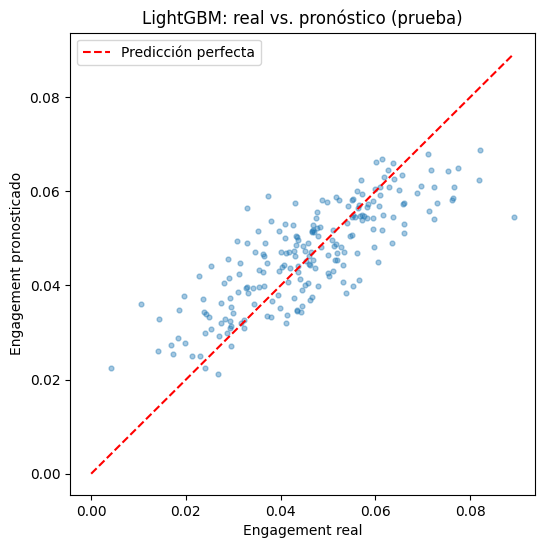

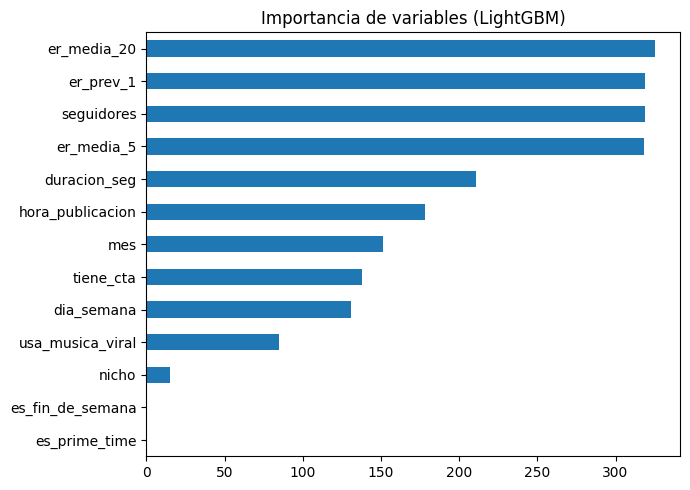

   duracion_seg  hora_publicacion  usa_musica_viral  tiene_cta  \
0            15                12                 1          1   
1            15                20                 1          1   
2            30                12                 0          0   
3            30                20                 1          1   

   engagement_pronosticado  
0                 0.056917  
1                 0.066826  
2                 0.037220  
3                 0.067280  


In [3]:

# Predicción del engagement de Reels con Machine Learning
# SAMUEL DAVID CELIS JEREMICHE
#TRABAJO FINAL

# %% [Celda 1] Instalación (solo la primera vez en Colab)
# !pip install -q lightgbm shap
# %% [Celda 2] Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb
SEED = 42
np.random.seed(SEED)
# %% [Celda 3] Datos
# OPCIÓN A: usa tus datos reales (exporta Meta Business Suite / Insights a CSV)
#   Columnas mínimas: fecha, cliente, nicho, duracion_seg, hora_publicacion,
#   usa_musica_viral, tiene_cta, seguidores, alcance, interacciones
# from google.colab import files
# subido = files.upload()
# df = pd.read_csv(next(iter(subido)), parse_dates=["fecha"])
# OPCIÓN B: datos SIMULADOS para probar el pipeline (por defecto)
def simular_datos(n=1500):
    clientes = {"restaurante": 8000, "gimnasio": 5000, "joyeria": 12000,
                "laboratorio": 3000, "industrial": 2000}
    filas = []
    fechas = pd.date_range("2024-01-01", periods=n, freq="12h")
    for f in fechas:
        nicho = np.random.choice(list(clientes))
        seguidores = clientes[nicho] * (1 + (f - fechas[0]).days / 900)
        dur = np.random.choice([7, 10, 15, 20, 30, 45, 60])
        hora = np.random.choice([8, 12, 14, 18, 19, 20, 21])
        musica = np.random.binomial(1, 0.5)
        cta = np.random.binomial(1, 0.4)
        base = 0.035 + 0.012 * musica + 0.008 * cta
        base += 0.010 * (hora in (19, 20, 21)) - 0.0002 * max(dur - 20, 0)
        base += 0.006 * (nicho == "restaurante") - 0.012 * (nicho ==
"industrial")
        base += 0.008 * (f.month == 2 or f.month == 12)  # temporadas
        er = max(base + np.random.normal(0, 0.008), 0.002)
        alcance = seguidores * np.random.uniform(0.6, 2.2)
        filas.append([f, nicho, dur, hora, musica, cta, int(seguidores),
                      int(alcance), int(alcance * er)])
    return pd.DataFrame(filas, columns=["fecha", "nicho", "duracion_seg",
        "hora_publicacion", "usa_musica_viral", "tiene_cta", "seguidores",
        "alcance", "interacciones"])
df = simular_datos()
df["engagement_rate"] = df["interacciones"] / df["alcance"]   # variable objetivo
print(df.shape); df.head()
# %% [Celda 4] Ingeniería de características
df = df.sort_values("fecha").reset_index(drop=True)
df["dia_semana"] = df["fecha"].dt.dayofweek
df["mes"] = df["fecha"].dt.month
df["es_fin_de_semana"] = (df["dia_semana" ] >= 5).astype(int)
df["es_prime_time"] = df["hora_publicacion"].between(19, 21).astype(int)
df["nicho"] = df["nicho"].astype("category")
# Historial del nicho SIN usar el futuro (shift evita fuga de información)
g = df.groupby("nicho", observed=True)["engagement_rate"]
df["er_prev_1"] = g.shift(1)
df["er_media_5"] = g.transform(lambda s: s.shift(1).rolling(5).mean())
df["er_media_20"] = g.transform(lambda s: s.shift(1).rolling(20).mean())
df = df.dropna().reset_index(drop=True)
VARIABLES = ["nicho", "duracion_seg", "hora_publicacion", "usa_musica_viral",
             "tiene_cta", "seguidores", "dia_semana", "mes",
             "es_fin_de_semana", "es_prime_time",
             "er_prev_1", "er_media_5", "er_media_20"]
OBJETIVO = "engagement_rate"
# %% [Celda 5] División temporal (el orden cronológico NO se mezcla)
corte_val = int(len(df) * 0.70)
corte_test = int(len(df) * 0.85)
train, val, test = df.iloc[:corte_val], df.iloc[corte_val:corte_test], df.iloc[corte_test:]
print(len(train), len(val), len(test))
# %% [Celda 6] Métricas
def wape(y, p):
    return np.abs(y - p).sum() / y.sum()
def reporte(nombre, y, p):
    mae = mean_absolute_error(y, p)
    rmse = np.sqrt(mean_squared_error(y, p))
    print(f"{nombre:<22} MAE={mae:.4f}  RMSE={rmse:.4f}  WAPE={wape(y, p):.2%}")
    return wape(y, p)
# %% [Celda 7] Línea base: promedio histórico del nicho (modelo "ingenuo")
media_nicho = train.groupby("nicho", observed=True)[OBJETIVO].mean()
p_base = test["nicho"].map(media_nicho).astype(float)
w_base = reporte("Línea base (nicho)", test[OBJETIVO], p_base)
# %% [Celda 8] Modelos comparados
X_tr, y_tr = train[VARIABLES], train[OBJETIVO]
X_va, y_va = val[VARIABLES], val[OBJETIVO]
X_te, y_te = test[VARIABLES], test[OBJETIVO]
# Ridge y Random Forest necesitan variables numéricas
def a_numerico(X):
    return pd.get_dummies(X, columns=["nicho"], dtype=float)
cols_num = a_numerico(X_tr).columns
ridge = Ridge(alpha=1.0).fit(a_numerico(X_tr), y_tr)
p_ridge = ridge.predict(a_numerico(X_te).reindex(columns=cols_num, fill_value=0))
reporte("Ridge", y_te, p_ridge)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                           random_state=SEED, n_jobs=-1)
rf.fit(a_numerico(X_tr), y_tr)
p_rf = rf.predict(a_numerico(X_te).reindex(columns=cols_num, fill_value=0))
reporte("Random Forest", y_te, p_rf)
# %% [Celda 9] LightGBM con validación cruzada temporal
tscv = TimeSeriesSplit(n_splits=5)
wapes = []
for i, (tr_idx, va_idx) in enumerate(tscv.split(X_tr), 1):
    m = lgb.LGBMRegressor(objective="regression_l1", num_leaves=31,
                          learning_rate=0.05, n_estimators=400,
                          random_state=SEED, verbose=-1)
    m.fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
    w = wape(y_tr.iloc[va_idx], m.predict(X_tr.iloc[va_idx]))
    wapes.append(w); print(f"Partición {i}: WAPE = {w:.2%}")
print(f"WAPE medio CV temporal: {np.mean(wapes):.2%}")
# Modelo final: entrena con train, detiene con val, evalúa en test
modelo = lgb.LGBMRegressor(objective="regression_l1", num_leaves=31,
                           learning_rate=0.05, n_estimators=1000,
                           random_state=SEED, verbose=-1)
modelo.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
           callbacks=[lgb.early_stopping(50, verbose=False)])
p_lgb = modelo.predict(X_te)
w_lgb = reporte("LightGBM", y_te, p_lgb)
# %% [Celda 10] ¿Se cumple el criterio de éxito? (mejora >= 15 % vs. base)
mejora = (w_base - w_lgb) / w_base
print(f"Mejora del WAPE frente a la línea base: {mejora:.1%}")
print("Criterio de éxito:", "CUMPLIDO" if mejora >= 0.15 else "NO cumplido")
# %% [Celda 11] Real vs. pronóstico
plt.figure(figsize=(6, 6))
plt.scatter(y_te, p_lgb, alpha=0.4, s=12)
lim = [0, max(y_te.max(), p_lgb.max())]
plt.plot(lim, lim, "r--", label="Predicción perfecta")
plt.xlabel("Engagement real"); plt.ylabel("Engagement pronosticado")
plt.title("LightGBM: real vs. pronóstico (prueba)"); plt.legend(); plt.show()
# %% [Celda 12] Importancia de variables
imp = pd.Series(modelo.feature_importances_, index=VARIABLES).sort_values()
imp.plot.barh(figsize=(7, 5), title="Importancia de variables (LightGBM)")
plt.tight_layout(); plt.show()
# Explicación con SHAP (opcional):
# import shap
# shap.summary_plot(shap.TreeExplainer(modelo).shap_values(X_te), X_te)
# %% [Celda 13] Usarlo: ¿qué Reel rinde más? (planeación de contenido)
nuevo = pd.DataFrame({
    "nicho": pd.Categorical(["restaurante"] * 4,
categories=df["nicho"].cat.categories),
    "duracion_seg": [15, 15, 30, 30],
    "hora_publicacion": [12, 20, 12, 20],
    "usa_musica_viral": [1, 1, 0, 1],
    "tiene_cta": [1, 1, 0, 1],
    "seguidores": [9000] * 4,
    "dia_semana": [4, 4, 4, 4], "mes": [2] * 4,
    "es_fin_de_semana": [0] * 4, "es_prime_time": [0, 1, 0, 1],
    "er_prev_1": [0.05] * 4, "er_media_5": [0.05] * 4, "er_media_20": [0.05] * 4,
})[VARIABLES]
nuevo["engagement_pronosticado"] = modelo.predict(nuevo)
print(nuevo[["duracion_seg", "hora_publicacion", "usa_musica_viral",
             "tiene_cta", "engagement_pronosticado"]])